# Daily Challenge: Classification with Neural Networks in TensorFlow

In this challenge I build neural networks with TensorFlow/Keras that separate two circles of points (the `make_circles` dataset). I start with a model that is too simple, then improve it step by step and look at its **decision boundary** to see what it learned.

## Objectives

**What I learn**
- The different types of classification: binary, multi-class and multi-label
- How to build a neural network for classification using TensorFlow
- How to improve model performance by adding layers, neurons and activation functions
- How to visualize decision boundaries to understand model predictions

**What I create**
- A neural network model for classification using TensorFlow
- Visualizations of the data distribution and of decision boundaries
- A model performance evaluation on training and test sets
- An experiment with activation functions and optimizers

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run the cells from top to bottom. The dataset is generated by scikit-learn, so there is no file to upload. I set random seeds so my results can be repeated.

**How to read this notebook:** before every code cell there is a short **"What this cell does"** note, the code has a comment on each important line, and after the key outputs there is a **"What this shows"** note.

### The Keras workflow used in every model below
Every model in this notebook follows the same 4 steps, so it helps to know them once:

| Step | Keras code | What it means |
|:--|:--|:--|
| 1. Build | `model = tf.keras.Sequential([...])` | A **Sequential** model is a stack of layers: the output of one layer is the input of the next. |
| | `tf.keras.layers.Dense(n, activation=...)` | A **Dense** layer has `n` neurons, and each neuron is connected to every input. Each neuron computes `activation(w·x + b)`. |
| 2. Compile | `model.compile(loss=..., optimizer=..., metrics=[...])` | Chooses **how to measure the error** (loss), **how to update the weights** (optimizer) and **what to report** (metrics such as accuracy). Nothing is trained yet. |
| 3. Fit | `history = model.fit(X, y, epochs=...)` | **Trains** the model. One **epoch** = one full pass over the training data. `history.history` stores the loss and accuracy of every epoch. |
| 4. Evaluate / predict | `model.evaluate(X, y)` / `model.predict(X)` | `evaluate` returns `[loss, accuracy]` on data. `predict` returns the model's output, here a probability between 0 and 1 for each point. |

## 1. Understand Classification Types

**Binary classification:** each example belongs to **one of two** classes. The model outputs one probability (sigmoid output) and I use a threshold such as 0.5. *Example:* an email is spam or not spam. The circles dataset in this notebook is binary too: a point is on the outer circle (0) or the inner circle (1). Loss: **binary crossentropy**.

**Multi-class classification:** each example belongs to **exactly one of three or more** classes. The model outputs one probability per class with a softmax, and the probabilities add up to 1. *Example:* recognizing which digit (0–9) is in an MNIST image, as in yesterday's challenge. Loss: **categorical crossentropy** (or sparse categorical crossentropy for integer labels).

**Multi-label classification:** each example can have **several labels at the same time, or none**. The model has one sigmoid output per label, and each label is decided on its own. *Example:* tagging a movie as "action", "comedy" and "romance", where one movie can have several genres. Loss: **binary crossentropy applied to every label**.

## 2. Set Up the Python Environment and the Dataset

**What this cell does:** imports the libraries from the instructions. NumPy handles arrays, pandas makes small tables, Matplotlib draws plots, TensorFlow builds and trains the networks, and `make_circles` generates the dataset. `tf.keras.utils.set_random_seed(42)` fixes the random numbers in NumPy, Python and TensorFlow (for example the starting weights), so I get the same results every run.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import make_circles

tf.keras.utils.set_random_seed(42)      # same starting weights and shuffling every run
print("TensorFlow:", tf.__version__)

I0000 00:00:1794916781.265070  216994 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794916781.299419  216994 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794916782.154067  216994 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0


**What this cell does (code from the instructions):** creates 1000 points. `make_circles` puts them on two circles, one inside the other. `noise=0.03` moves each point slightly away from its perfect circle, and `random_state=42` makes the result repeatable.
- `X` has shape (1000, 2): one row per point, with 2 columns (the x1 and x2 coordinates). These are the **features**.
- `y` has shape (1000,): one label per point, **0 = outer circle**, **1 = inner circle**. This is the **target**.

In [2]:
from sklearn.datasets import make_circles

samples = 1000
X, y = make_circles(samples,
                    noise = 0.03,
                    random_state = 42)

print('X : ', X)
print('\n')
print('y : ', y)

X :  [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 ...
 [-0.13690036 -0.81001183]
 [ 0.67036156 -0.76750154]
 [ 0.28105665  0.96382443]]


y :  [1 1 1 1 0 1 1 1 1 0 1 0 1 1 1 1 0 1 1 0 1 0 0 1 0 0 0 1 1 1 0 0 1 0 0 0 1
 1 1 0 0 0 0 1 0 0 1 1 0 1 1 1 0 1 0 0 1 0 0 1 0 0 1 0 1 1 1 1 0 1 0 0 1 1
 0 0 1 0 1 0 1 0 0 0 0 1 1 1 1 0 0 0 1 0 1 0 1 0 0 1 1 0 1 0 1 1 1 1 0 1 1
 1 1 1 0 0 0 1 1 0 1 0 1 0 0 1 1 0 1 1 1 1 0 1 1 0 0 0 0 0 0 0 1 0 1 1 1 0
 1 0 1 0 1 0 1 0 0 1 0 1 1 1 1 1 1 1 0 1 0 0 0 0 0 1 0 0 0 0 1 1 0 1 0 1 1
 0 0 0 1 1 1 1 1 0 0 0 0 0 1 0 0 1 1 1 1 1 0 1 0 1 0 0 1 1 1 0 1 0 1 1 0 1
 1 0 1 0 1 0 1 1 0 1 0 1 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 1 0 0 1 1 1
 0 1 0 0 0 0 1 1 0 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 0 0 1 1 1 1 0 0 0
 1 0 0 0 1 0 0 0 1 1 0 1 1 1 1 1 1 1 0 0 0 0 1 0 0 0 0 1 1 1 0 0 1 0 1 0 1
 1 0 0 1 1 1 1 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 1
 0 1 0 0 0 1 0 0 1 1 0 0 1 0 0 1 1 0 1 1 0 0 1 0 1 0 0 0 1 1 0 0 1 1 1

**What this cell does:** checks the shapes and the class balance, and shows the first rows as a table so the numbers are easier to read.

In [3]:
print("X shape:", X.shape, "| y shape:", y.shape)
print("points per class:", {int(k): int(v) for k, v in zip(*np.unique(y, return_counts=True))})   # how many 0s and 1s
circles = pd.DataFrame({"X1": X[:, 0], "X2": X[:, 1], "label": y})
circles.head()

X shape: (1000, 2) | y shape: (1000,)
points per class: {0: 500, 1: 500}


,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0


**What this shows:** there are exactly 500 points of each class, so the classes are balanced. That also means a model that guesses randomly (or always predicts the same class) gets about **50% accuracy**. That is the number to beat.

**What this cell does:** draws every point at its (X1, X2) position and colours it by its label, so I can see the shape of the problem.

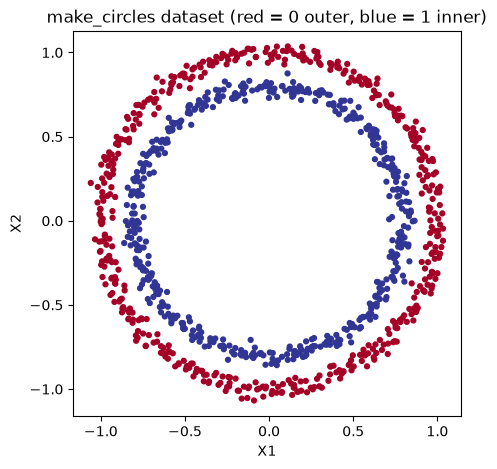

In [4]:
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, s=12)   # colour = label (red = 0, blue = 1)
plt.title("make_circles dataset (red = 0 outer, blue = 1 inner)")
plt.xlabel("X1"); plt.ylabel("X2"); plt.axis("equal")
plt.show()

**What this shows:** one class forms a ring around the other. **No straight line can separate the two classes**, so the model needs to learn a curved (circular) boundary. Keep this in mind for steps 3 and 4.

## 3. Build a Basic Neural Network Model

**What this cell does:** builds the simplest possible network, as the instructions ask: a `Sequential` model with **one Dense layer**.
- `layers.Input(shape=(2,))` tells Keras that each example has 2 numbers (X1, X2).
- `Dense(1, activation="sigmoid")` is a single neuron that computes `sigmoid(w1·X1 + w2·X2 + b)`. The sigmoid squeezes the result into a probability between 0 and 1 (the probability of class 1).
- `compile`: the loss is **binary crossentropy** (the standard loss for 2 classes, it is large when the model is confident and wrong), the optimizer is **SGD** (plain stochastic gradient descent), and I track **accuracy**.
- `fit(X, y, epochs=100)`: 100 passes over the data. By default Keras uses mini-batches of 32 points, so the weights are updated 32 times per epoch (1000 / 32 ≈ 32 batches). `verbose=0` hides the per-epoch printout. I print the last epoch myself.

In this step I train on all 1000 points, as the instructions do. The proper train/test split comes in step 7.

In [5]:
tf.keras.utils.set_random_seed(42)

model_1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),                   # 2 input features: X1, X2
    tf.keras.layers.Dense(1, activation="sigmoid"),      # 1 neuron -> probability of class 1
])

model_1.compile(loss=tf.keras.losses.BinaryCrossentropy(),     # error measure for 2 classes
                optimizer=tf.keras.optimizers.SGD(),           # plain gradient descent (learning rate 0.01)
                metrics=["accuracy"])                          # % of points classified correctly

history_1 = model_1.fit(X, y, epochs=100, verbose=0)          # train for 100 epochs
print(f"last epoch -> loss: {history_1.history['loss'][-1]:.4f}, accuracy: {history_1.history['accuracy'][-1]:.4f}")

loss_1, acc_1 = model_1.evaluate(X, y, verbose=0)              # evaluate returns [loss, accuracy]
print(f"model_1 evaluated on all points -> loss: {loss_1:.4f}, accuracy: {acc_1:.4f}")
model_1.summary()                                              # layers and number of parameters

last epoch -> loss: 0.6934, accuracy: 0.4960
model_1 evaluated on all points -> loss: 0.6933, accuracy: 0.4970


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

**What this shows:** after 100 epochs the accuracy is **0.497** and the loss is **0.693**. A loss of 0.693 = ln(2) is exactly what binary crossentropy gives when the model predicts about 0.5 for every point, which means "I don't know". The summary shows why: the model has only **3 trainable parameters** (2 weights + 1 bias). One neuron with a sigmoid can only draw a **straight line** between the classes, and no straight line can separate a ring from the circle inside it. So this model is no better than a coin flip.

## 4. Improve the Model

The instructions suggest three changes: **more layers and neurons**, **more epochs**, and **Adam instead of SGD**. To see what each change can and cannot do, I apply all three **but keep the default (linear) activation in the hidden layers**. Activation functions are the topic of step 6.

**What this cell does:**
- builds a model with two hidden `Dense` layers of 10 neurons and a sigmoid output neuron,
- compiles it with **Adam**, an optimizer that adapts the step size of each weight automatically (learning rate 0.01, 10× the Keras default of 0.001, to speed things up),
- trains it for **200 epochs** instead of 100.

In [6]:
tf.keras.utils.set_random_seed(42)

model_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(10),                          # hidden layer 1: 10 neurons, NO activation (linear)
    tf.keras.layers.Dense(10),                          # hidden layer 2: 10 neurons, NO activation (linear)
    tf.keras.layers.Dense(1, activation="sigmoid"),     # output: probability of class 1
])
model_2.compile(loss="binary_crossentropy",
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),   # Adam instead of SGD
                metrics=["accuracy"])
history_2 = model_2.fit(X, y, epochs=200, verbose=0)                     # more epochs
loss_2, acc_2 = model_2.evaluate(X, y, verbose=0)
print(f"model_2 -> loss: {loss_2:.4f}, accuracy: {acc_2:.4f}")
print("trainable parameters:", model_2.count_params())

model_2 -> loss: 0.6932, accuracy: 0.5000
trainable parameters: 151


**What this shows:** even with 151 parameters, Adam and twice as many epochs, the accuracy is still **0.500** (loss 0.693). The reason is that layers **without an activation function** are linear, and stacking linear layers just gives another linear function. So the whole network can still only draw a straight line, exactly like model 1. More layers, more epochs and a better optimizer cannot fix a model that is not able to represent the right shape.

## 5. Visualize the Decision Boundary

**What this cell does:** defines `plot_decision_boundary(model, X, y)`. The idea: ask the model for a prediction at *every* point of a fine grid that covers the data, and colour the plane by the predicted class. The line where the colour changes is the **decision boundary**.
1. `np.meshgrid` builds a 100 × 100 grid of (x1, x2) positions that covers the data, with a small margin.
2. `np.c_[xx.ravel(), yy.ravel()]` turns the grid into a list of 10,000 points with shape (10000, 2), the same format as `X`.
3. `model.predict` returns a probability for each grid point. I round it with a 0.5 threshold to get class 0 or 1.
4. `plt.contourf` colours the regions, and `plt.scatter` draws the real points on top.

A `title` argument lets me reuse the function for every model.

In [7]:
def plot_decision_boundary(model, X, y, title=None):
    # 1) grid limits: a little wider than the data
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))      # two 100x100 arrays
    # 2) every grid position as one row (x1, x2) -> shape (10000, 2)
    x_in = np.c_[xx.ravel(), yy.ravel()]
    # 3) predicted probability for each grid point, then class with a 0.5 threshold
    y_prob = model.predict(x_in, verbose=0)                   # shape (10000, 1)
    y_pred = np.round(y_prob).reshape(xx.shape)               # back to 100x100
    # 4) coloured regions + the real points
    plt.contourf(xx, yy, y_pred, cmap=plt.cm.RdYlBu, alpha=0.7)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=12, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.2)
    plt.xlim(xx.min(), xx.max()); plt.ylim(yy.min(), yy.max())
    if title: plt.title(title)

**What this cell does:** draws the decision boundaries of the two models so far, side by side (`plt.subplot(1, 2, k)` = 1 row, 2 columns, plot number k).

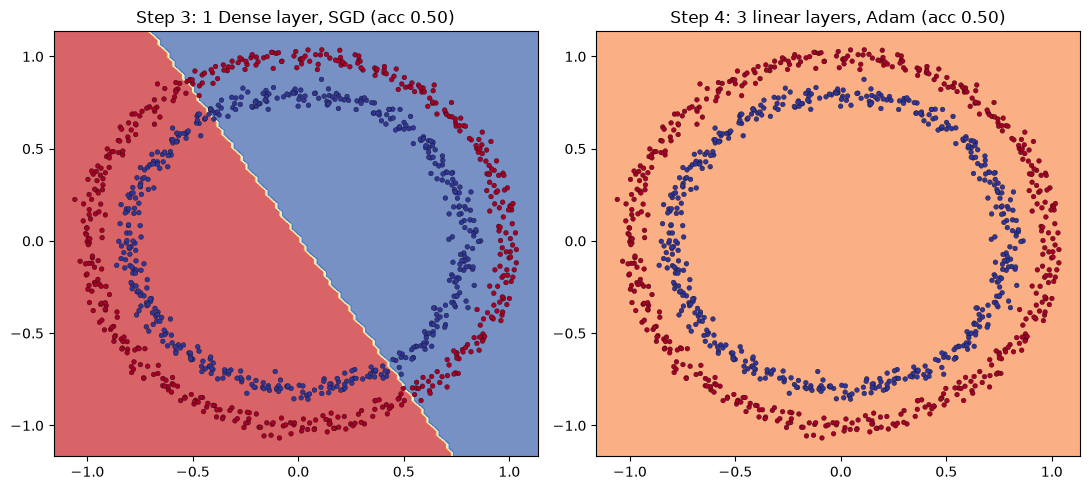

In [8]:
plt.figure(figsize=(11, 5))
plt.subplot(1, 2, 1); plot_decision_boundary(model_1, X, y, f"Step 3: 1 Dense layer, SGD (acc {acc_1:.2f})")
plt.subplot(1, 2, 2); plot_decision_boundary(model_2, X, y, f"Step 4: 3 linear layers, Adam (acc {acc_2:.2f})")
plt.tight_layout(); plt.show()

**What this shows:** the boundaries confirm the numbers. Model 1 (left) splits the plane with a **straight diagonal line**, so each side contains half of both circles. Model 2 (right) is a single colour: it predicts the same class for the whole plane. Neither model can follow the circular shape of the data.

## 6. Incorporate Activation Functions

An **activation function** is applied to each neuron's weighted sum. Without one, stacking layers is useless, because a linear function of a linear function is still linear.
- **ReLU** (`max(0, z)`): keeps positive values and turns negative values into 0. It is the usual choice for hidden layers. It is cheap to compute and adds the "bend" a network needs to draw curves.
- **Sigmoid** (`1 / (1 + e^-z)`): squeezes any number into the range (0, 1). It is the usual choice for the **output** neuron in binary classification, because the result can be read as a probability.

**What this cell does:** plots both functions on the range -10 to 10 using TensorFlow's own implementations (`tf.keras.activations.relu` and `.sigmoid`).

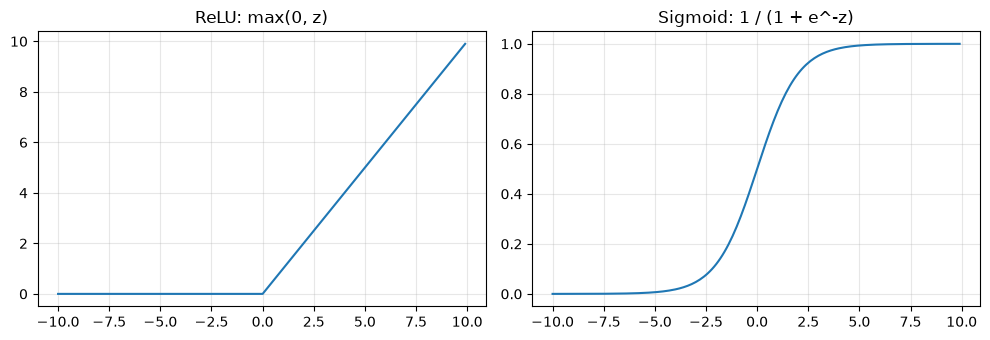

In [9]:
z = tf.cast(tf.range(-10, 10, 0.1), tf.float32)       # input values from -10 to 10
plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1); plt.plot(z, tf.keras.activations.relu(z));    plt.title("ReLU: max(0, z)"); plt.grid(alpha=0.3)
plt.subplot(1, 2, 2); plt.plot(z, tf.keras.activations.sigmoid(z)); plt.title("Sigmoid: 1 / (1 + e^-z)"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**What this cell does:** builds the same architecture as in step 4, but now the two hidden layers use **ReLU** and the output uses **sigmoid**. Compile and fit are the same (Adam, learning rate 0.01, 200 epochs on all points), so the only change from model 2 is the activation function. This makes the comparison fair.

                                  model   loss  accuracy
       1: 1 Dense, sigmoid, SGD, 100 ep 0.6933     0.497
2: 3 Dense, linear hidden, Adam, 200 ep 0.6932     0.500
  3: 3 Dense, ReLU hidden, Adam, 200 ep 0.0003     1.000


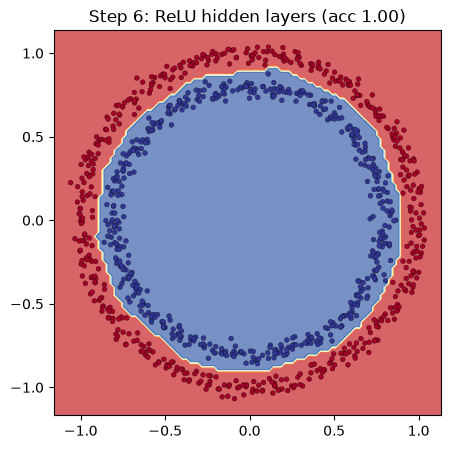

In [10]:
tf.keras.utils.set_random_seed(42)

model_3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(10, activation="relu"),       # hidden layer 1 with ReLU (non-linear)
    tf.keras.layers.Dense(10, activation="relu"),       # hidden layer 2 with ReLU
    tf.keras.layers.Dense(1, activation="sigmoid"),     # output probability
])
model_3.compile(loss="binary_crossentropy",
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
                metrics=["accuracy"])
history_3 = model_3.fit(X, y, epochs=200, verbose=0)
loss_3, acc_3 = model_3.evaluate(X, y, verbose=0)

comparison = pd.DataFrame({
    "model": ["1: 1 Dense, sigmoid, SGD, 100 ep", "2: 3 Dense, linear hidden, Adam, 200 ep", "3: 3 Dense, ReLU hidden, Adam, 200 ep"],
    "loss": [loss_1, loss_2, loss_3],
    "accuracy": [acc_1, acc_2, acc_3],
}).round(4)
print(comparison.to_string(index=False))

plt.figure(figsize=(5, 5))
plot_decision_boundary(model_3, X, y, f"Step 6: ReLU hidden layers (acc {acc_3:.2f})")
plt.show()

**What this shows:** changing **only** the hidden activations from linear to ReLU takes the accuracy from **0.500 to 1.000**, and the loss from 0.693 to 0.0003. ReLU lets each hidden neuron bend the space, and combining 10 of these bends lets the network draw a closed, roughly circular boundary around the inner class (the decision boundary plot shows the blue region around the inner points). Sigmoid stays on the output so the result is still a probability. *Note:* this is still measured on the data it was trained on. The real test is in steps 7–8.

## 7. Split Data into Training and Testing Sets

So far every model was trained and evaluated on the same 1000 points, which can hide overfitting. Now I do it properly.

**What this cell does:** `train_test_split` shuffles the data and keeps **80% (800 points) for training** and **20% (200 points) for testing**. `stratify=y` keeps the 50/50 class balance in both parts, and `random_state=42` makes the split repeatable. The test points are never used for training. They are used only once, at the end, to check how well the model works on new data.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", X_train.shape, y_train.shape, "| test:", X_test.shape, y_test.shape)
print("class counts train:", np.bincount(y_train), "test:", np.bincount(y_test))

train: (800, 2) (800,) | test: (200, 2) (200,)
class counts train: [400 400] test: [100 100]


**What this cell does:** trains the improved model (same architecture as model 3: ReLU hidden layers, sigmoid output, Adam) on the **training set only**.
- `validation_split=0.1` holds back the last 10% of the training points (80 points) and checks the model on them after each epoch, so I can watch for overfitting while training. The model is not trained on them.
- `epochs=100` is enough here (model 3 had converged well before 200 epochs).

In [12]:
tf.keras.utils.set_random_seed(42)

model_final = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(10, activation="relu"),
    tf.keras.layers.Dense(10, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
model_final.compile(loss="binary_crossentropy",
                    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
                    metrics=["accuracy"])
history_final = model_final.fit(X_train, y_train, epochs=100,
                                validation_split=0.1,      # 10% of the training set for monitoring
                                verbose=0)
h = history_final.history                                  # dict: loss, accuracy, val_loss, val_accuracy
print(f"last epoch -> train loss {h['loss'][-1]:.4f}, train acc {h['accuracy'][-1]:.4f}, "
      f"val loss {h['val_loss'][-1]:.4f}, val acc {h['val_accuracy'][-1]:.4f}")

last epoch -> train loss 0.0015, train acc 1.0000, val loss 0.0002, val acc 1.0000


**What this cell does:** plots the loss and accuracy of every epoch, from `history_final.history`, for the training part and the validation part.

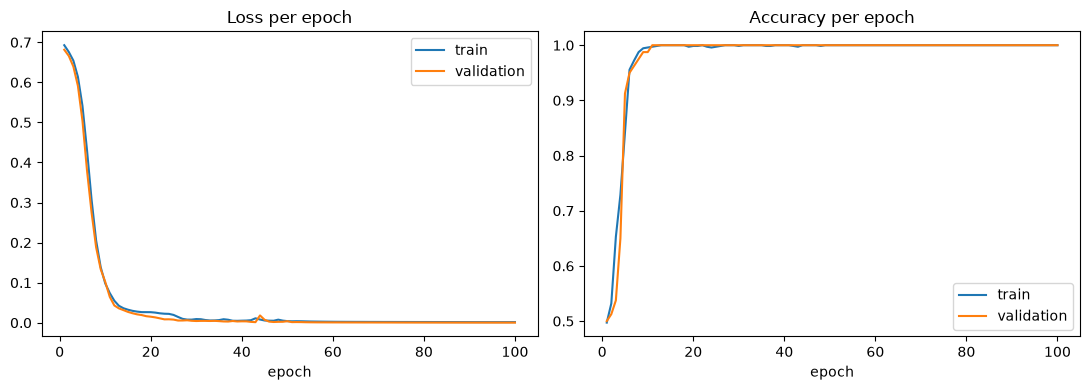

In [13]:
ep = range(1, len(h["loss"]) + 1)
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1); plt.plot(ep, h["loss"], label="train"); plt.plot(ep, h["val_loss"], label="validation")
plt.title("Loss per epoch"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(ep, h["accuracy"], label="train"); plt.plot(ep, h["val_accuracy"], label="validation")
plt.title("Accuracy per epoch"); plt.xlabel("epoch"); plt.legend()
plt.tight_layout(); plt.show()

**What this shows:** the loss falls fast during the first ~15 epochs, and the accuracy goes from about 0.50 to almost 1.00 in that time. After that both curves are flat. The **training and validation curves stay on top of each other** the whole time (last epoch: train accuracy 1.0000, validation accuracy 1.0000), so there is **no sign of overfitting**. The model learned the circular rule, not the individual points.

## 8. Evaluate and Visualize Final Model Performance

**What this cell does:** `model_final.evaluate(X_test, y_test)` runs the trained model on the 200 test points it has never seen, and returns the **loss** and the **accuracy**. I also compute the training-set numbers to compare them.

In [14]:
train_loss, train_acc = model_final.evaluate(X_train, y_train, verbose=0)
test_loss, test_acc = model_final.evaluate(X_test, y_test, verbose=0)
print(f"Training set -> loss: {train_loss:.4f}, accuracy: {train_acc:.4f}")
print(f"Test set     -> loss: {test_loss:.4f}, accuracy: {test_acc:.4f}")

# how many of the 200 test points are wrong?
test_pred = (model_final.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)   # probability -> class
print("misclassified test points:", int((test_pred != y_test).sum()), "of", len(y_test))

Training set -> loss: 0.0009, accuracy: 1.0000
Test set     -> loss: 0.0021, accuracy: 1.0000
misclassified test points: 0 of 200


**What this cell does:** uses `plot_decision_boundary()` on the training data and on the test data, as the instructions ask.

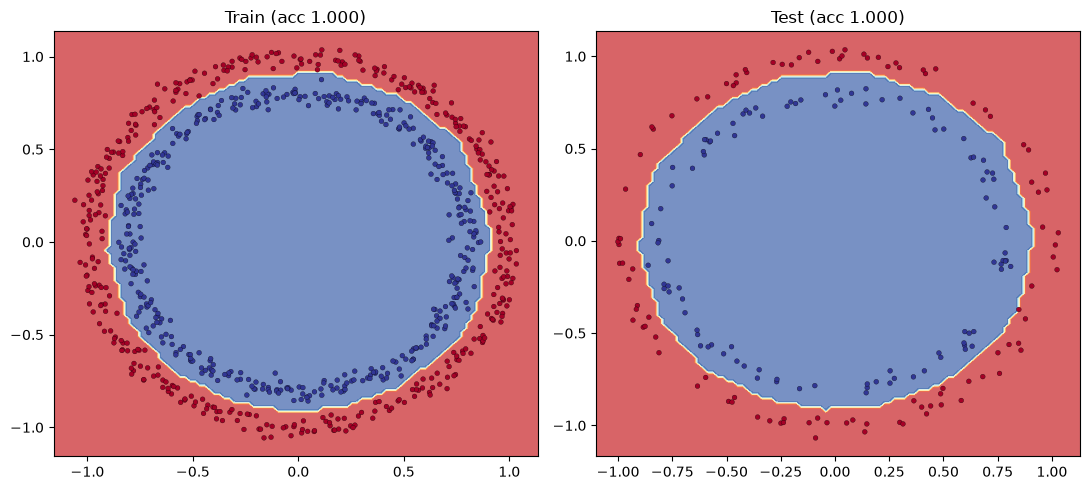

In [15]:
plt.figure(figsize=(11, 5))
plt.subplot(1, 2, 1); plot_decision_boundary(model_final, X_train, y_train, f"Train (acc {train_acc:.3f})")
plt.subplot(1, 2, 2); plot_decision_boundary(model_final, X_test, y_test, f"Test (acc {test_acc:.3f})")
plt.tight_layout(); plt.show()

**What this shows / comparison:** the final model reaches **test accuracy 1.000 (0 of 200 test points misclassified)**, with a test loss of **0.0021**. The training numbers are almost the same (accuracy 1.000, loss 0.0009), so the model generalizes to new points. In both plots the blue region is a closed, slightly jagged ring that sits in the gap between the two circles, and the boundary drawn from the training points also separates the unseen test points. Compared with step 3 (0.497) and step 4 (0.500), the gain comes from the **non-linear activation functions**. The extra layers and Adam only helped once the model could bend. *Honest note:* with only 0.03 noise the two circles do not overlap at all, so 100% is possible here. With more noise (e.g. `noise=0.1`), some points would fall on the wrong side and the accuracy would be lower.

## 9. Summary: Key Takeaways

- **Look at the data first.** The scatter plot showed right away that the classes form a ring, so a linear model could not work. Without that plot, the 50% accuracy of models 1 and 2 would have been confusing.
- **Capacity is not only size.** Model 2 had 50× more parameters than model 1, plus Adam and more epochs, and it was still stuck at 50%. Without non-linear activations, extra layers add nothing.
- **Activation functions are what let a network learn curves.** ReLU in the hidden layers + sigmoid on the output took the accuracy from 0.50 to 1.00, with everything else unchanged.
- **Hyperparameters matter, but in the right order.** The architecture and activations set what the model *can* learn. The optimizer (Adam vs SGD), the learning rate and the number of epochs set how quickly and how well it gets there.
- **Evaluate on data the model has not seen.** The 80/20 split, the validation curves and the test decision boundary show that the final model generalizes: test accuracy 1.000 and test loss 0.0021, with training and validation curves that stay together.
- **Decision boundaries make a model understandable.** One plot shows what a model has learned (a line, nothing, or a circle) much faster than a table of numbers.